# 03 · Generic Tyre Model (all circuits)

Notebook 01 analyses **one** race. This notebook uses **every dry race on OpenF1 (2023 onwards)** to predict tyre wear for any upcoming race, and passes the result to notebook 02 for the pit strategy.

**Pipeline**
1. Download all races → data-quality report
2. EDA
3. Layered outlier removal
4. **Per-race tyre model**: separates tyre wear from fuel burn and track evolution
5. Compare predictors (history model, Ridge, decision tree, random forest, gradient boosting) with **forward-chaining validation**: each 2025–26 race is predicted using only the races before it
6. Hold-out check on the target circuit → predict the target race → save for notebook 02

In [1]:
# --- Setup (works locally or on Colab) ---
import sys, os
if "google.colab" in sys.modules and not os.path.exists("f1strat"):
    REPO = "https://github.com/anerudh-k/f1-tyre-strategy"
    !git clone -q {REPO} repo && cp -r repo/* .
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1strat import *
COLORS = {"SOFT": "#e10600", "MEDIUM": "#f5c400", "HARD": "#8a8a8a"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
os.makedirs("figures", exist_ok=True); os.makedirs("data", exist_ok=True)

In [2]:
# --- Config ---
YEARS = (2023, 2024, 2025, 2026)            # seasons to learn from (OpenF1 starts in 2023)
TARGET_YEAR, TARGET_GP = 2026, "Las Vegas"  # race to predict (accents optional)
TEST_FROM = 202501                          # validation: predict every race from 2025 R1 on

## 1. Build the dataset
The first run downloads every race (about 15 min). Everything is cached in `data/cache/`, so later runs take seconds and only new races are downloaded.
Races that were cancelled or haven't happened yet show as *skipped*. That's expected.

In [3]:
laps, races = build_dataset(YEARS)
laps.to_pickle("data/generic_laps.pkl"); races.to_pickle("data/generic_races.pkl")
print(f"\n{(races.Status == 'ok').sum()} races loaded | {races.Status.str.startswith('skipped').sum()} skipped | "
      f"{races.Status.str.startswith('FAILED').sum()} failed | {len(laps):,} clean laps")

2023 R01 Bahrain Grand Prix                    1058 raw ->   895 clean
2023 R02 Saudi Arabian Grand Prix               945 raw ->   812 clean
2023 R03 Australian Grand Prix                 1006 raw ->   741 clean
2023 R04 Azerbaijan Grand Prix                  963 raw ->   812 clean
2023 R05 Miami Grand Prix                      1139 raw ->  1059 clean
2023 R06 Emilia Romagna Grand Prix            skipped - no lap data on OpenF1 (race cancelled or not published)
2023 R07 Monaco Grand Prix                     1516 raw ->   970 clean  (wet)
2023 R08 Spanish Grand Prix                    1312 raw ->  1187 clean
2023 R09 Canadian Grand Prix                   1318 raw ->  1088 clean
2023 R10 Austrian Grand Prix                   1355 raw ->  1141 clean
2023 R11 British Grand Prix                     974 raw ->   768 clean
2023 R12 Hungarian Grand Prix                  1255 raw ->  1142 clean
2023 R13 Belgian Grand Prix                     817 raw ->   704 clean
2023 R14 Dutch Grand Prix    

C:\Users\Anerudh K\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


2025 R22 Las Vegas Grand Prix                   888 raw ->   738 clean
2025 R23 Qatar Grand Prix                      1070 raw ->   887 clean
2025 R24 Abu Dhabi Grand Prix                  1156 raw ->  1062 clean
2026 R01 Australian Grand Prix                 1008 raw ->   826 clean
2026 R02 Chinese Grand Prix                     924 raw ->   798 clean
2026 R03 Japanese Grand Prix                   1108 raw ->   884 clean
2026 R04 Bahrain Grand Prix                   skipped - no lap data on OpenF1 (race cancelled or not published)
2026 R05 Saudi Arabian Grand Prix             skipped - no lap data on OpenF1 (race cancelled or not published)
2026 R06 Miami Grand Prix                      1042 raw ->   830 clean
2026 R07 Canadian Grand Prix                   1212 raw ->  1039 clean
2026 R08 Monaco Grand Prix                     1452 raw ->  1069 clean
2026 R09 Barcelona Grand Prix                  1241 raw ->  1037 clean
2026 R10 Austrian Grand Prix                   1342 raw ->  1163 c

## 2. Data quality check

In [4]:
# Anything that isn't a normal dry race
races[(races.Status != "ok") | races.Rain.eq(True)][["Year", "Round", "EventName", "Status", "WetLaps", "Rain"]]

,Year,Round,EventName,Status,WetLaps,Rain
5,2023,6,Emilia Romagna Grand Prix,skipped: no lap data on OpenF1 (race cancelled...,NaN,NaN
6,2023,7,Monaco Grand Prix,ok,462.0,True
13,2023,14,Dutch Grand Prix,ok,327.0,True
31,2024,9,Canadian Grand Prix,ok,827.0,True
34,2024,12,British Grand Prix,ok,234.0,True
43,2024,21,São Paulo Grand Prix,ok,1135.0,True
47,2025,1,Australian Grand Prix,ok,683.0,True
58,2025,12,British Grand Prix,ok,607.0,True
74,2026,4,Bahrain Grand Prix,skipped: no lap data on OpenF1 (race cancelled...,NaN,NaN
75,2026,5,Saudi Arabian Grand Prix,skipped: no lap data on OpenF1 (race cancelled...,NaN,NaN


In [5]:
ok = races[races.Status == "ok"].copy()
ok["KeptPct"] = (100 * ok.CleanLaps / ok.RawLaps).round(1)
print("Median % of laps kept by basic cleaning:", ok.KeptPct.median())
print("Missing values per race feature:", ok[["MedianLap", "STSpeed", "I1Speed", "I2Speed", "S1Share",
      "S2Share", "TrackTemp", "PitLoss"]].isna().sum().to_dict())
ok[["RaceId", "TotalLaps", "RawLaps", "CleanLaps", "KeptPct", "SCLaps", "HadSC", "Rain", "PitLoss",
    "TrackTemp"]].sort_values("KeptPct").head(15).round(2)

Median % of laps kept by basic cleaning: 84.9
Missing values per race feature: {'MedianLap': 0, 'STSpeed': 0, 'I1Speed': 0, 'I2Speed': 0, 'S1Share': 0, 'S2Share': 0, 'TrackTemp': 0, 'PitLoss': 4}


,RaceId,TotalLaps,RawLaps,CleanLaps,KeptPct,SCLaps,HadSC,Rain,PitLoss,TrackTemp
43,2024_21_Interlagos,69.0,1137.0,0.0,0.0,13.0,True,True,NaN,25.77
47,2025_01_Melbourne,58.0,928.0,82.0,8.8,26.0,True,True,20.83,18.94
58,2025_12_Silverstone,52.0,827.0,126.0,15.2,17.0,True,True,24.38,23.58
31,2024_09_Montreal,70.0,1272.0,284.0,22.3,12.0,True,True,20.79,24.57
88,2026_18_Kuala Lumpur,55.0,1145.0,614.0,53.6,14.0,True,False,26.08,34.40
13,2023_14_Zandvoort,72.0,1344.0,746.0,55.5,12.0,True,True,30.33,24.94
92,2026_22_Interlagos,71.0,1437.0,804.0,55.9,2.0,False,True,24.42,26.07
45,2024_23_Lusail,57.0,944.0,584.0,61.9,21.0,True,False,26.97,22.77
6,2023_07_Monte Carlo,79.0,1516.0,970.0,64.0,2.0,False,True,18.28,39.26
34,2024_12_Silverstone,52.0,962.0,616.0,64.0,1.0,False,True,31.18,27.67


## 3. Exploratory data analysis

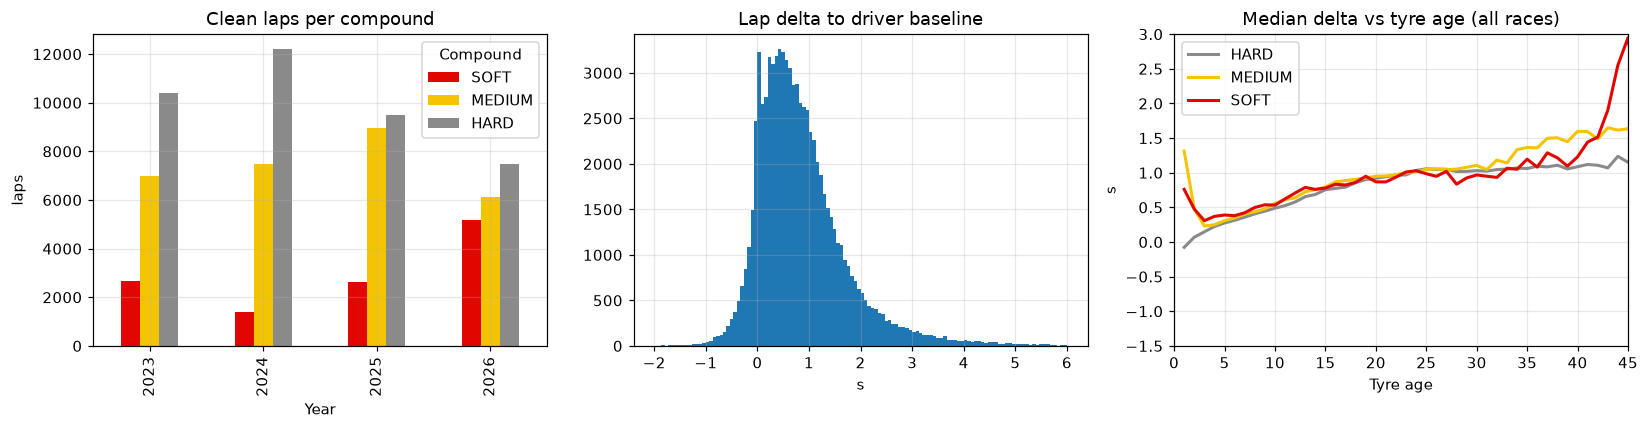

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
laps.groupby(["Year", "Compound"]).size().unstack()[list(COLORS)].plot.bar(ax=ax[0], color=COLORS)
ax[0].set(title="Clean laps per compound", ylabel="laps")
ax[1].hist(laps[TARGET], bins=120, range=(-2, 6)); ax[1].set(title="Lap delta to driver baseline", xlabel="s")
for c, g in laps.groupby("Compound"):
    b = g.groupby("TyreLife")[TARGET].median()
    ax[2].plot(b.index, b.values, c=COLORS[c], lw=2, label=c)
ax[2].set(title="Median delta vs tyre age (all races)", xlabel="Tyre age", ylabel="s", xlim=(0, 45), ylim=(-1.5, 3))
ax[2].legend(); plt.tight_layout(); plt.savefig("figures/eda_overview.png", bbox_inches="tight")

Stints: 3945 | median stint slope by compound (s/lap): {'HARD': 0.047, 'MEDIUM': 0.049, 'SOFT': 0.059}


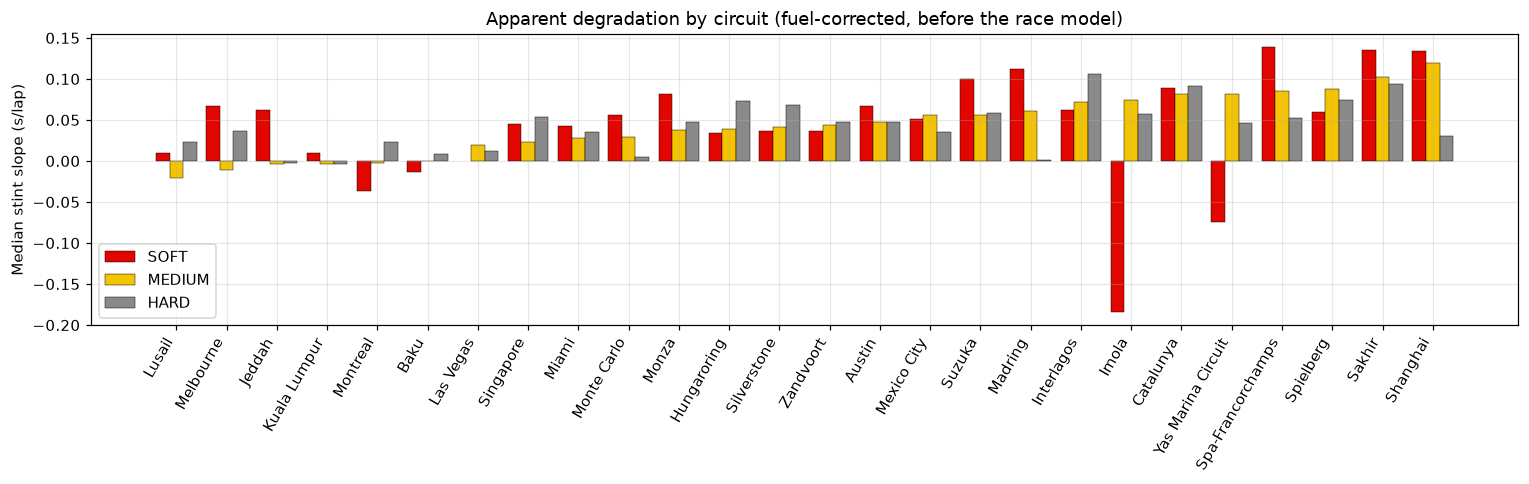

In [7]:
# Lap-to-lap noise: how far single laps scatter around their own stint's trend
sl = stint_slopes(laps)
print("Stints:", len(sl), "| median stint slope by compound (s/lap):",
      sl.groupby("Compound").Slope.median().round(3).to_dict())
order = sl[sl.Compound == "MEDIUM"].groupby("Circuit").Slope.median().sort_values().index
fig, ax = plt.subplots(figsize=(14, 4.5))
for i, c in enumerate(["SOFT", "MEDIUM", "HARD"]):
    m = sl[sl.Compound == c].groupby("Circuit").Slope.median().reindex(order)
    ax.bar(np.arange(len(m)) + (i - 1) * 0.27, m.values, 0.27, color=COLORS[c], label=c, edgecolor="k", lw=0.3)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=60, ha="right")
ax.set(ylabel="Median stint slope (s/lap)", title="Apparent degradation by circuit (fuel-corrected, before the race model)")
ax.legend(); plt.tight_layout(); plt.savefig("figures/eda_deg_by_circuit.png", bbox_inches="tight")

## 4. Outlier removal
Layered, so every step's effect is visible:
1. **Wet races** (more than 10% of laps on inters/wets): different physics
2. **Races with < 200 clean laps**
3. **Stints < 5 laps** and **impossible stint slopes** (|slope| > 0.4 s/lap): stint or compound data errors. Checked before step 4, so trimming laps can't hide a bad stint.
4. **Lap outliers**: robust z-score (median/MAD, which the outliers can't distort) of each lap's residual from its race/compound trend, |z| > 3.5. Catches traffic, mistakes and timing glitches.
5. **Tyre ages above the 99th percentile** per compound: too few laps to learn from

                step  laps_left  removed
               start      80994        0
           wet races      77366     3628
    races < 200 laps      77366        0
     stints < 5 laps      76789      577
   stint |slope|>0.4      76449      340
lap residual |z|>3.5      74331     2118
      tyre age > p99      73616      715
    missing features      73616        0


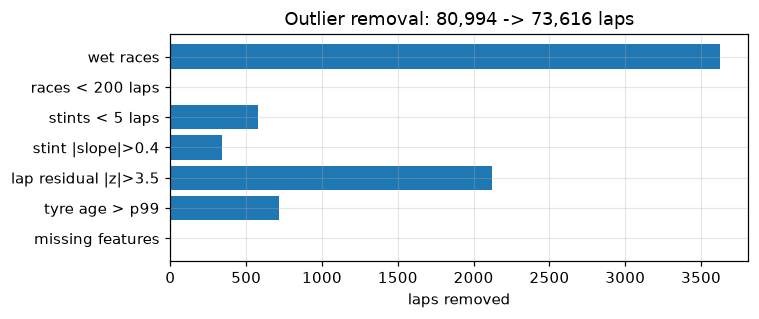

In [8]:
d, report = clean_dataset(laps, races)
fig, ax = plt.subplots(figsize=(7, 3)); ax.barh(report.step[1:], report.removed[1:]); ax.invert_yaxis()
ax.set(xlabel="laps removed", title=f"Outlier removal: {len(laps):,} -> {len(d):,} laps"); plt.tight_layout()
plt.savefig("figures/outlier_removal.png", bbox_inches="tight")

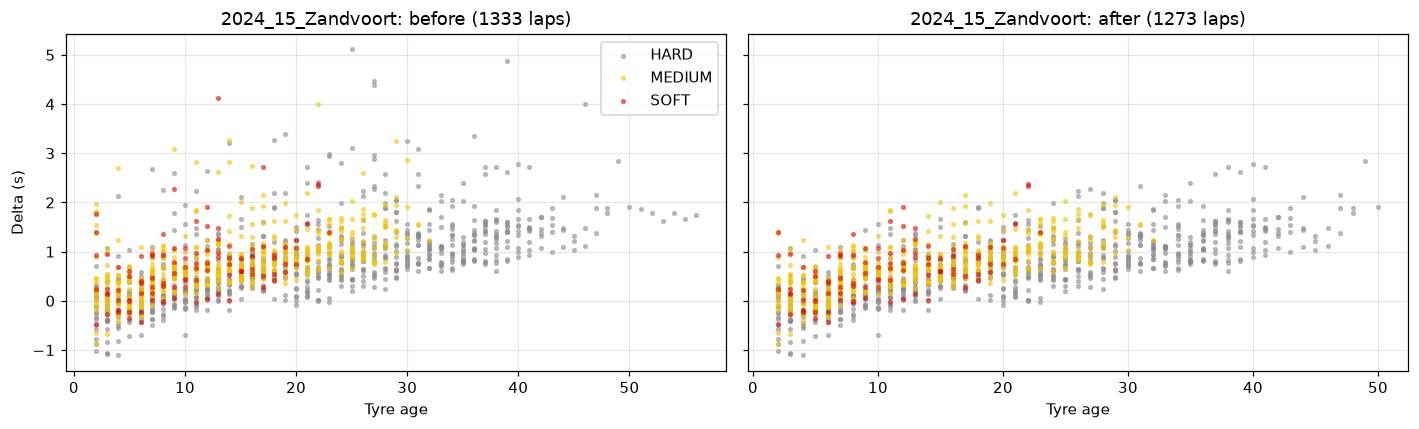

In [9]:
rid = d.RaceId.value_counts().index[0]
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, src, t in [(ax[0], laps, "before"), (ax[1], d, "after")]:
    g = src[src.RaceId == rid]
    for c, gg in g.groupby("Compound"):
        a.scatter(gg.TyreLife, gg[TARGET], s=6, alpha=0.5, c=COLORS[c], label=c)
    a.set(title=f"{rid}: {t} ({len(g)} laps)", xlabel="Tyre age")
ax[0].set_ylabel("Delta (s)"); ax[0].legend(); plt.tight_layout(); plt.savefig("figures/outliers_before_after.png", bbox_inches="tight")

## 5. Per-race tyre model: separating tyre wear from fuel and track evolution
Within one stint, **tyre age and lap number rise together**. Fuel burn and the track getting faster both depend on lap number and are worth about −0.05 s/lap, the same size as tyre wear. Fitting a stint on its own mixes the two together (that's why notebook 01 showed the Hard wearing faster than the Soft).

Each race is therefore fitted as one robust regression:

$$t_{\text{lap}} = \underbrace{\alpha_{\text{driver}}}_{\text{pace}} + \underbrace{\delta_{c}}_{\text{compound offset}} + \underbrace{\beta\cdot\text{lap}}_{\text{fuel + track}} + \underbrace{w_c \cdot \text{age}}_{\text{tyre wear}}$$

Stints that start at different laps make $\beta$ and $w_c$ separable. Estimates with large uncertainty (everyone pitted at the same lap) are dropped.

In [10]:
L = race_table(d, races)
L.to_pickle("data/race_tyre_table.pkl")
print(f"\n{L.RaceId.nunique()} races, {len(L)} race x compound wear estimates")
L.groupby("Compound")[["Wear", "SE", "Offset", "LapEffect", "MaxAge"]].median().round(3)

193 race x compound estimates, 9 dropped as unreliable
                   RaceId Compound   Wear    SE
        2023_03_Melbourne   MEDIUM  4.439 0.007
        2023_03_Melbourne     HARD  4.375 0.008
        2023_16_Singapore     SOFT  0.041 0.022
           2024_04_Suzuka     SOFT  0.147 0.021
        2025_11_Spielberg     SOFT  0.057 0.018
2025_13_Spa-Francorchamps   MEDIUM -9.326 0.006
2025_13_Spa-Francorchamps     HARD -9.344 0.007
      2025_14_Hungaroring     SOFT  0.068 0.021
          2026_16_Madring     SOFT -0.036 0.019

80 races, 184 race x compound wear estimates


,Wear,SE,Offset,LapEffect,MaxAge
Compound,,,,,
HARD,0.045,0.003,0.101,-0.058,31.7
MEDIUM,0.052,0.004,0.000,-0.057,25.0
SOFT,0.055,0.005,-0.090,-0.053,24.0


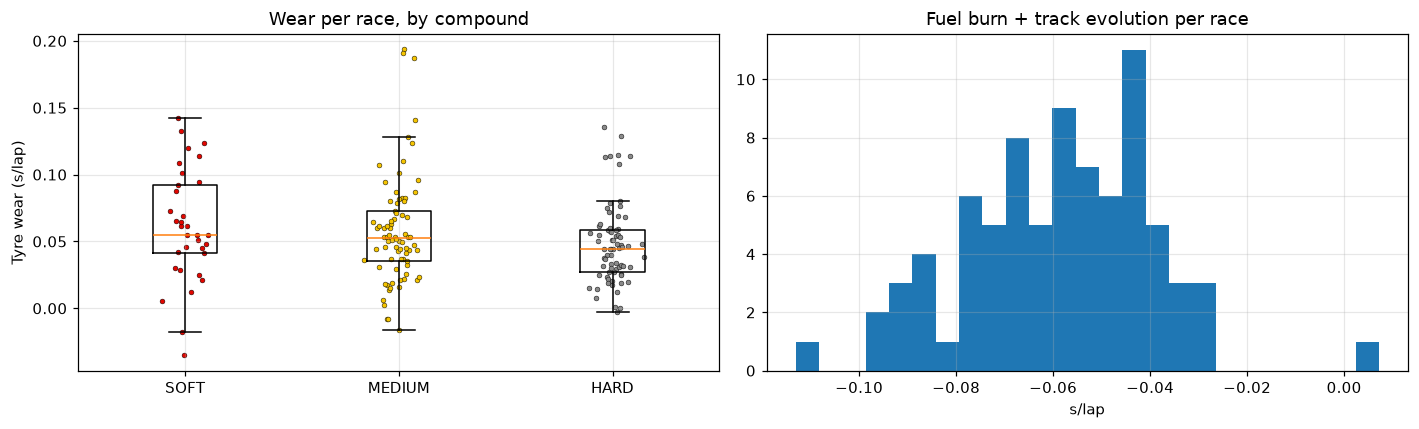

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].boxplot([L[L.Compound == c].Wear for c in COLORS], showfliers=False)
ax[0].set_xticks([1, 2, 3]); ax[0].set_xticklabels(list(COLORS))
for i, c in enumerate(COLORS):
    x = L[L.Compound == c].Wear; ax[0].scatter(np.random.normal(i + 1, 0.05, len(x)), x, s=10, c=COLORS[c], edgecolor="k", lw=0.3)
ax[0].set(ylabel="Tyre wear (s/lap)", title="Wear per race, by compound")
ax[1].hist(L.drop_duplicates("RaceId").LapEffect, bins=25)
ax[1].set(xlabel="s/lap", title="Fuel burn + track evolution per race")
plt.tight_layout(); plt.savefig("figures/race_model_wear.png", bbox_inches="tight")

In [12]:
# How consistent is a circuit's wear from year to year?
piv = L[L.Compound == "MEDIUM"].pivot_table(index="Circuit", columns="Year", values="Wear")
print("MEDIUM wear (s/lap) by circuit and year"); piv.round(3)

MEDIUM wear (s/lap) by circuit and year


Year,2023,2024,2025,2026
Circuit,,,,
Austin,0.073,0.037,0.045,0.080
Baku,0.029,0.053,0.016,0.019
Catalunya,0.056,0.082,0.055,0.191
Hungaroring,0.043,0.066,0.050,0.052
Imola,NaN,0.069,0.054,NaN
Interlagos,0.060,NaN,0.053,NaN
Jeddah,0.002,0.047,0.065,NaN
Kuala Lumpur,NaN,NaN,NaN,0.050
Las Vegas,0.053,0.188,0.031,NaN


## 6. Model comparison
Can a race's tyre wear be predicted **before the race**? Every race from `TEST_FROM` on is predicted using **only earlier races** (forward-chaining), exactly how the model would be used before a weekend.

| Model | What it uses |
|---|---|
| Compound average | the median wear of each compound over all past races |
| **History model** | this circuit's past races, shrunk toward this season's average (few past races → trust the season average more) |
| Ridge / Decision tree / Random forest / Gradient boosting | circuit features (speed traps, sector shares, lap time, temperatures), compound, 2026 era **plus** the history model's prediction |

**Test_MAE** = error on races the model hadn't seen. **Overfit_gap** = test − train error (large = memorising).

In [13]:
results, preds = compare_models(L, TEST_FROM)
results.round(4)

,Model,Test_MAE,Test_R2,Train_MAE,Overfit_gap,N_test
0,Circuit history (HistoryModel),0.0238,0.1051,0.0252,-0.0014,97
1,Random forest (features + history),0.0240,0.0702,0.0155,0.0086,97
2,Ridge (features + history),0.0251,-0.0544,0.0248,0.0004,97
3,Gradient boosting (features + history),0.0253,-0.0582,0.0089,0.0163,97
4,Compound average,0.0255,-0.0381,0.0264,-0.0009,97
5,Decision tree (features + history),0.0275,-0.2508,0.0194,0.0081,97


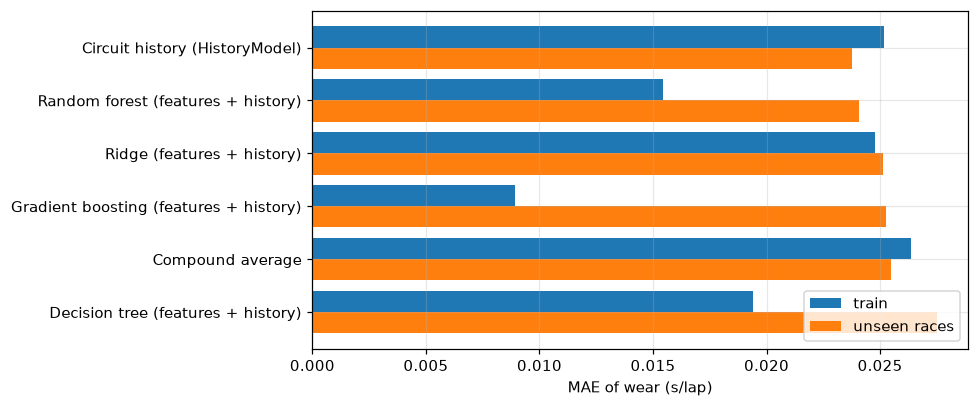

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.8)); y = np.arange(len(results))
ax.barh(y - 0.2, results.Train_MAE, 0.4, label="train"); ax.barh(y + 0.2, results.Test_MAE, 0.4, label="unseen races")
ax.set_yticks(y); ax.set_yticklabels(results.Model); ax.invert_yaxis(); ax.set(xlabel="MAE of wear (s/lap)")
ax.legend(); plt.tight_layout(); plt.savefig("figures/model_comparison.png", bbox_inches="tight")

,depth,train_MAE,test_MAE
0,1,0.0251,0.0263
1,2,0.0217,0.0314
2,3,0.0187,0.0310
3,4,0.0164,0.0325
4,5,0.0143,0.0337
5,6,0.0131,0.0340
6,7,0.0121,0.0344
7,8,0.0115,0.0343
8,9,0.0112,0.0344
9,10,0.0109,0.0343


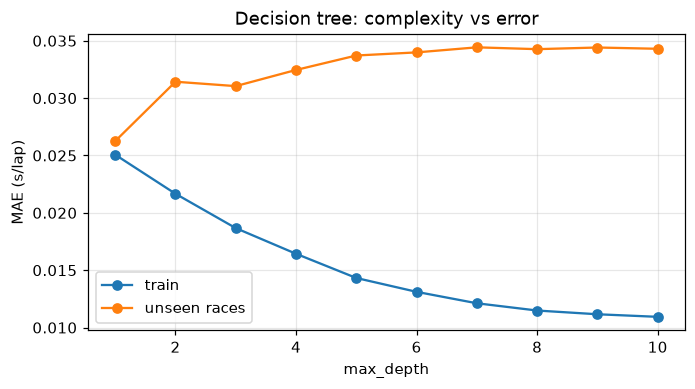

In [15]:
# Overfitting check: decision tree depth vs error
curve = tree_depth_curve(L, test_from=TEST_FROM)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(curve.depth, curve.train_MAE, "o-", label="train"); ax.plot(curve.depth, curve.test_MAE, "o-", label="unseen races")
ax.set(xlabel="max_depth", ylabel="MAE (s/lap)", title="Decision tree: complexity vs error"); ax.legend()
plt.savefig("figures/tree_depth_curve.png", bbox_inches="tight"); curve.round(4)

In [16]:
# Which inputs matter? (random forest, permutation importance)
feature_importance(L).round(4)

,Feature,MAE_increase,std
0,History,0.0064,0.0009
1,S2Share,0.0033,0.0004
2,I1Speed,0.0024,0.0003
3,MedianLap,0.0023,0.0003
4,S1Share,0.0020,0.0003
5,STSpeed,0.0014,0.0001
6,TrackTemp,0.0013,0.0001
7,AirTemp,0.0012,0.0001
8,I2Speed,0.0008,0.0001
9,CompoundCode,0.0002,0.0000


## 7. Hold-out check on the target circuit
Predict the circuit's most recent race using only the races before it, and compare with what the race model measured.

In [17]:
hm = HistoryModel().fit(L)
holdout_check(L, races, TARGET_GP, hm).round(3)

,Race,Compound,Actual_wear,Predicted_wear,Compound_avg,Error
0,2025_22_Las Vegas,MEDIUM,0.031,0.079,0.053,0.048
1,2025_22_Las Vegas,HARD,0.025,0.042,0.045,0.017


## 8. Predict the target race and save it for notebook 02

{'Circuit': 'Las Vegas', 'Editions': 3, 'TotalLaps': 50, 'PitLoss': 23.03400000000002, 'P_SC': 0.3333333333333333}


,Compound,Model,PaceOffset_s,Deg_s_per_lap,CV_RMSE_s,Laps,MaxAgeSeen,CliffAge
0,SOFT,history,-0.046,0.0434,0.024,33,24,None
1,MEDIUM,history,0.072,0.0723,0.024,78,21,None
2,HARD,history,0.179,0.0427,0.024,73,27,None


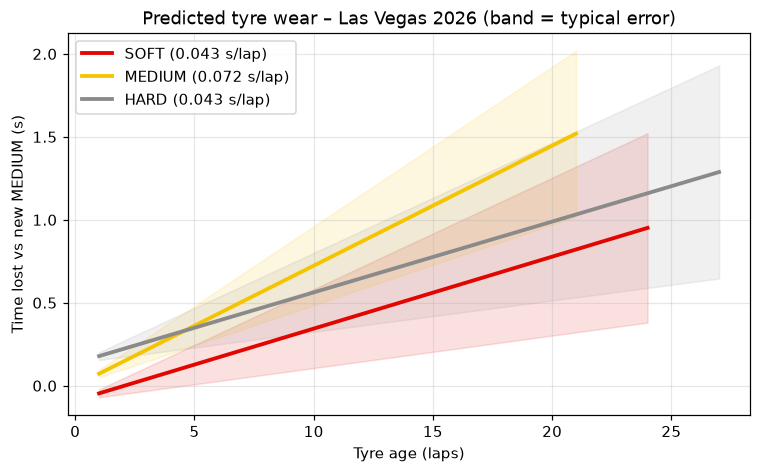

In [18]:
circuit = resolve_circuit(races, TARGET_GP)
profile = track_profile(races, TARGET_GP)
CV_MAE = float(results.set_index("Model").loc["Circuit history (HistoryModel)", "Test_MAE"])
pred = predict_deg_models(hm, circuit, TARGET_YEAR, cv_mae=CV_MAE)
print(profile)
display(summary_table(pred))
fig, ax = plt.subplots(figsize=(8, 4.5))
for c, m in pred.items():
    a = np.arange(1, m.max_age_seen + 1)
    ax.plot(a, m.predict(a), c=COLORS[c], lw=2.5, label=f"{c} ({m.deg_per_lap:.3f} s/lap)")
    ax.fill_between(a, m.predict(a) - CV_MAE * a, m.predict(a) + CV_MAE * a, color=COLORS[c], alpha=0.12)
ax.set(xlabel="Tyre age (laps)", ylabel="Time lost vs new MEDIUM (s)",
       title=f"Predicted tyre wear – {circuit} {TARGET_YEAR} (band = typical error)")
ax.legend(); plt.savefig("figures/predicted_target.png", bbox_inches="tight")

In [19]:
tag = str(TARGET_GP).lower().replace(" ", "_")
out = f"data/deg_generic_{TARGET_YEAR}_{tag}.json"
save_models(pred, out, meta=dict(year=TARGET_YEAR, gp=TARGET_GP, event=f"{circuit} {TARGET_YEAR} (generic model)",
            total_laps=profile["TotalLaps"], pit_loss_est=profile["PitLoss"], p_sc=profile["P_SC"],
            wear_sd=CV_MAE, model="HistoryModel", trained_on=list(YEARS)))
print("saved", out, "-> set MODEL_FILE to this in notebook 02")

saved data/deg_generic_2026_las_vegas.json -> set MODEL_FILE to this in notebook 02


## Findings
*(Your own words, from your results.)*
- **Measurement:** fuel + track evolution is worth about −0.06 s/lap, the same size as tyre wear. Separating the two (section 5) puts the compounds in the right order (Soft > Medium > Hard).
- **Predictability:** how much better the history model is than the compound average on unseen races, and how small the R² is. Most race-to-race variation isn't predictable from past data.
- **Overfitting:** the tree models' train/test gap and the depth curve. Circuit features add nothing on top of the circuit's own history.
- **Hold-out** result for the target circuit.
- **Limitations:** OpenF1 gives SOFT/MEDIUM/HARD, not Pirelli's C1–C5; 2026 is a new regulation era; linear wear (no cliff); the best extra information would be this weekend's long runs or sprint race.